# Reweighting towards a target radius of gyration (GROMACS)

A single experimental value, such as the radius of gyration (Rg) from SAXS, can be used to reweight a simulation. The Rg of each frame computed with `gmx gyrate` is read directly from the `.xvg` file with `load_xvg`, giving the target value and its error:

```
gmx gyrate -f traj.xtc -s topol.tpr -o gyrate.xvg
```

`gmx gyrate` writes Rg in nm, so target and error must be in nm too. Column 1 of the file (the default) is the total Rg; other columns can be selected with `column=`.

The data used here are **synthetic**: a protein with a compact state (Rg ≈ 1.35 nm) and an extended state (Rg ≈ 1.85 nm). The simulation under-samples the extended state (about 15% of the frames), while the "experiment" was generated from a 50/50 mixture, with Rg = 1.60 ± 0.05 nm. To use your own data, change the file names and the target.

In [1]:
import sys,os
import numpy as np
import matplotlib.pyplot as plt
bme_dir = os.getcwd().split("notebook")[0]
sys.path.insert(0,bme_dir)
import BME as BME

xvg_file = "%s/data/rg_example.xvg" % bme_dir
target, sigma = 1.60, 0.05   # nm

rew = BME.Reweight("example_06")
time = rew.load_xvg(xvg_file, target=target, sigma=sigma)
rg = rew.get_calculated()[:,0]

print("frames: %d (time %.0f - %.0f ps)" % (len(time), time[0], time[-1]))
print("<Rg> simulation: %.3f nm, target %.2f +/- %.2f nm" % (rg.mean(), target, sigma))

frames: 5000 (time 0 - 499900 ps)
<Rg> simulation: 1.420 nm, target 1.60 +/- 0.05 nm


## Choosing theta

With a single data point the cross-validation of `theta_scan` (see example 2), which leaves out part of the data, cannot be used. Instead, we look at how the reweighted average and the fraction of effective frames (phi) change with theta. Small theta fits the target closely but moves far from the simulation (small phi); large theta stays close to the simulation. A reasonable choice is the largest theta for which the average is within the experimental error, i.e. |⟨Rg⟩ − target|/σ < 1.

In [2]:
thetas = [0.1, 0.3, 1, 3, 10, 30, 100]
print("%8s %8s %14s %8s %8s" % ("theta", "<Rg>", "(<Rg>-t)/sigma", "chi2", "phi"))
for theta in thetas:
    chi2_before, chi2_after, phi = rew.fit(theta=theta)
    avg = np.dot(rew.get_weights(), rg)
    print("%8g %8.3f %14.2f %8.3f %8.3f" % (theta, avg, (avg-target)/sigma, chi2_after, phi))

   theta     <Rg> (<Rg>-t)/sigma     chi2      phi
     0.1    1.599          -0.01    0.000    0.741
     0.3    1.598          -0.04    0.002    0.744
       1    1.593          -0.14    0.021    0.755
       3    1.580          -0.41    0.165    0.783
      10    1.544          -1.13    1.268    0.856
      30    1.490          -2.19    4.811    0.946
     100    1.446          -3.09    9.527    0.992


Here theta = 3 is the largest value with the average within one sigma of the target (theta = 10 is just outside), and it keeps almost 80% effective frames.

<Rg> before: 1.420 nm  after: 1.580 nm
CHI2 before: 12.889  after: 0.165
fraction of effective frames: 0.783
fraction of frames with Rg > 1.6 nm: 0.135 -> 0.396


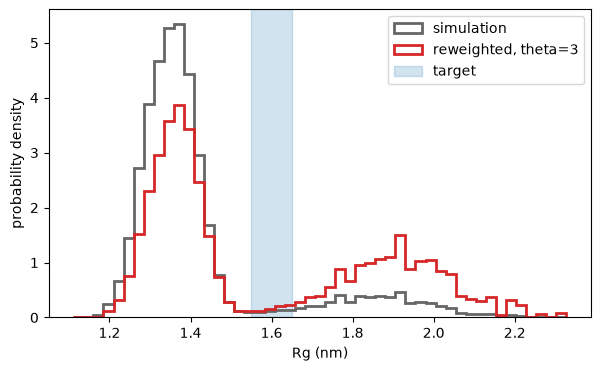

In [3]:
theta = 3
chi2_before, chi2_after, phi = rew.fit(theta=theta)
w0, w = rew.get_w0(), rew.get_weights()

print("<Rg> before: %.3f nm  after: %.3f nm" % (np.dot(w0,rg), np.dot(w,rg)))
print("CHI2 before: %.3f  after: %.3f" % (chi2_before, chi2_after))
print("fraction of effective frames: %.3f" % phi)
print("fraction of frames with Rg > 1.6 nm: %.3f -> %.3f" % (np.sum(w0[rg>1.6]), np.sum(w[rg>1.6])))

bins = np.linspace(rg.min(), rg.max(), 50)
fig, ax = plt.subplots(figsize=(7,4))
ax.hist(rg, bins=bins, weights=w0, density=True, histtype="step", lw=2, color="0.4", label="simulation")
ax.hist(rg, bins=bins, weights=w, density=True, histtype="step", lw=2, color="C3", label="reweighted, theta=%g" % theta)
ax.axvspan(target-sigma, target+sigma, color="C0", alpha=0.2, label="target")
ax.set_xlabel("Rg (nm)")
ax.set_ylabel("probability density")
ax.legend()
plt.show()

The weights can be saved together with the time of each frame, e.g. to compute reweighted averages of other quantities or to use them as initial weights (example 5).

In [4]:
np.savetxt("example_06.weights.dat", np.column_stack([time, w]), fmt=["%.1f", "%.6e"], header="time(ps) weight")
print(open("example_06.weights.dat").read()[:200])

# time(ps) weight
0.0 1.378583e-04
100.0 1.705237e-04
200.0 1.101696e-04
300.0 1.059927e-04
400.0 1.538600e-04
500.0 1.723479e-04
600.0 1.506072e-04
700.0 1.325777e-04
800.0 1.827073e-04
900.0 1.25946


## Combining Rg with chemical shifts

A single average only constrains the mean: many different ensembles have the same ⟨Rg⟩. Other data can be added to the same `Reweight` object. Here 20 (synthetic) chemical shifts were computed on every 5th frame, so the Rg is read with `stride=5` so that both datasets refer to the same frames (an error is raised if the numbers of frames differ).

With many chemical shifts and one Rg, the Rg has little influence on the fit. The `weight` argument sets the relative importance of a dataset: a data point with `weight=k` counts as k data points (as if its error were divided by √k).

In [5]:
cs_exp = "%s/data/cs_example_exp.dat" % bme_dir
cs_calc = "%s/data/cs_example_calc.dat.zip" % bme_dir

rew2 = BME.Reweight("example_06_cs")
rew2.load(cs_exp, cs_calc)
rew2.load_xvg(xvg_file, target=target, sigma=sigma, stride=5, weight=5)
chi2_before, chi2_after, phi = rew2.fit(theta=3)
print("all data   CHI2 before: %.3f  after: %.3f   fraction of effective frames: %.3f" % (chi2_before, chi2_after, phi))

# statistics for each dataset: [chi2, rmsd, violations] before and after reweighting
stats_cs = rew2.predict(cs_exp, cs_calc)
stats_rg = rew2.predict_xvg(xvg_file, target, sigma, stride=5)
print("chem. shifts CHI2 before: %.3f  after: %.3f" % (stats_cs[0], stats_cs[3]))
print("Rg           CHI2 before: %.3f  after: %.3f" % (stats_rg[0], stats_rg[3]))

rg5 = rew2.get_calculated(columns=[-1])[:,0]
w5 = rew2.get_weights()
print("<Rg>: %.3f nm" % np.dot(w5, rg5))
print("fraction of frames with Rg > 1.6 nm: Rg only %.3f, Rg + chemical shifts %.3f" % (np.sum(w[rg>1.6]), np.sum(w5[rg5>1.6])))

all data   CHI2 before: 1.688  after: 0.032   fraction of effective frames: 0.662
chem. shifts CHI2 before: 1.122  after: 0.033
Rg           CHI2 before: 12.999  after: 0.001
<Rg>: 1.599 nm
fraction of frames with Rg > 1.6 nm: Rg only 0.396, Rg + chemical shifts 0.455


In the 50/50 ensemble used to generate the synthetic data, about 48% of the conformations have Rg > 1.6 nm. The Rg alone moves the simulation from 13% towards this value; the chemical shifts, which distinguish the two states, bring it closer.

Other options of `load_xvg`:
- `bound="UPPER"` or `"LOWER"`: the target is an upper or lower limit instead of an average;
- `begin`, `end`: use only frames in a time window (e.g. to discard equilibration);
- `use_samples`: use a list of frames;
- `column`: another column of the `.xvg` file (e.g. any other observable computed with GROMACS).